# Phase I – How does the model behave? (AI-aided pair)

**Pair:** Paul Mairhofer (k12312103), Fabian Matusek (k12111864) · team Organic Alpacas · JKU AI and Visualization, WS 2026

**Model:** the shared ResNet-18 checkpoint (`shared/outputs/resnet18/best_model.pth`), fine-tuned on PlantVillage, 38 classes.
**Data:** original PlantVillage test split (10,948 images), plus modified copies of a stratified test subset that we built for controlled tests.

**Black box only.** We use images, metadata, predicted labels, confidences, full probability vectors, and outputs on images we modified.
We do not use activations, embeddings, gradients, weights or saliency of the model (that is Phase II).
Where we describe the inputs with other measurements (pixel thumbnails, leaf masks, colour statistics), that describes the *images*, not the model.

**How this notebook was made.** The analysis, code and text were produced by an autonomous coding agent (Claude, via pi) from one prompt,
without human intervention during the run; see `ai-interactions/phase1/`. The notebook only reads cached results from `results/`
(no model inference); the scripts `01_...py` to `07_...py` in this folder recompute them (see `README.md`).

## Findings at a glance

| # | Question | Finding (numbers from this notebook) |
|---|---|---|
| 1 | How are confusions organised? | By crop first, disease second: 83 of 107 errors stay in the crop (chance 10%); 12 of the 24 cross-crop errors keep the disease name (potato <-> tomato blights). The runner-up of correct predictions shows the same structure (same crop 37%, chance 10%). |
| 2 | Are errors random photos? | No, they belong to leaves: 90 errors on 51 leaves (random: 85). If one photo of a leaf is wrong, 38% of its other photos are wrong too (0.4% otherwise). The 18 bacterial spot -> yellow leaf curl errors come from 7 pale, yellow leaves. |
| 3 | What do capture changes do? | Mild changes are fine (94-99%), strong ones break the model (darker x0.25: 25%, blur sigma 4: 22%, noise: 10%). Errors collapse into sinks: at strengths 3-4, 51% of 21,164 wrong predictions go to three tomato classes. Confidence stays high (31% of these errors > 0.9). |
| 4 | Why "Tomato late blight"? | A dark whole image sends 66% of other-class images there; a dark leaf (5%) or dark background (11%) alone rarely does. The training set has a late-blight session photographed dark on black (117 of its 118 images are in the darkest 1%). |
| 5 | Does the model use the background? | Partly: a foreign background lowers accuracy from 96% to 84%; with the leaf removed the model still names the class 12% of the time (chance 2.6%). The background colour alone carries a lot more (border-colour 15-NN: 51%). |
| 6 | Do near-duplicates explain the accuracy? | No: only 135 test images have a near-copy in training, 1 of them wrong; error rates barely depend on similarity to the training set. One near-copy pair looks mislabelled in the dataset. |

In [1]:
import json, io
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

import pv, viz, figures
viz.style()
FIG = pv.FIGURES
FIG.mkdir(exist_ok=True)
pd.set_option("display.width", 160)

sh, names = figures.load_shared()               # shared test predictions (10,948 rows)
hosts, dis, short, order = figures.class_meta(names)
rep = json.loads((pv.RESULTS / "reproduction_check.json").read_text())
print(f"reproduction: {rep['n_test'] - rep['pred_idx_mismatches']:,}/{rep['n_test']:,} identical predictions, "
      f"max |prob difference| {rep['max_abs_prob_diff']:.4f}")
print("only mismatch (a near-tie between two classes):", rep["mismatches"])

reproduction: 10,947/10,948 identical predictions, max |prob difference| 0.0027
only mismatch (a near-tie between two classes): [{'sample_idx': 7479, 'true_idx': 28, 'shared_top2': [[35, 0.48356], [28, 0.48181]], 'reproduced_top2': [[28, 0.48272], [35, 0.48262]]}]


**Reproduction check.** Before any analysis we reran the checkpoint on the test split on CPU (`01_reproduce_predictions.py`).
10,947 of 10,948 predictions are identical to `shared/outputs/resnet18/test_predictions.csv`, and the largest probability
difference is 0.0027. The one mismatch (sample 7479, true Tomato bacterial spot) is a near-tie between bacterial spot and
yellow leaf curl in both runs (shared: 0.484 vs 0.482; ours: 0.483 vs 0.483), so GPU versus CPU rounding flips it.
We therefore use the shared CSV for all analyses of the natural test set, and compare modified images with the same images run
through our CPU pipeline.

In [2]:
err = sh[~sh.correct]
cross = err[err.true_label.map(pv.host_of) != err.pred_label.map(pv.host_of)]
facts = {
    "test images": len(sh), "accuracy": round(sh.correct.mean(), 4), "errors": len(err),
    "errors within the crop": len(err) - len(cross), "errors across crops": len(cross),
    "errors with confidence > 0.9": int((err.confidence > 0.9).sum()),
    "correct with confidence < 0.9": int((sh.correct & (sh.confidence < 0.9)).sum()),
    "images without leaf grouping (leaf_grouped=False)": int((~sh.leaf_grouped).sum()),
    "smallest / largest class in test": f"{sh.true_idx.value_counts().min()} / {sh.true_idx.value_counts().max()}",
}
pd.Series(facts, name="value").to_frame()

,value
test images,10948
accuracy,0.9902
errors,107
errors within the crop,83
errors across crops,24
errors with confidence > 0.9,43
correct with confidence < 0.9,183
images without leaf grouping (leaf_grouped=False),3549
smallest / largest class in test,32 / 1156


## 1. Which classes does the model confuse, and how are the confusions organised?

With 107 errors in 10,948 images the confusion matrix is almost empty. The softmax probabilities still show which classes the model
finds similar: for every true class we average the probability that goes to each *wrong* class (a "soft" confusion matrix, following the
Lab 02 pointer to Alsallakh et al. 2020 for very accurate models). Classes are ordered by crop; potato and pepper sit next to tomato because they are
the same plant family. The bars on the right check the structure against chance: how is the wrong class (for errors) or the
second-ranked class (for correct predictions) related to the true class?

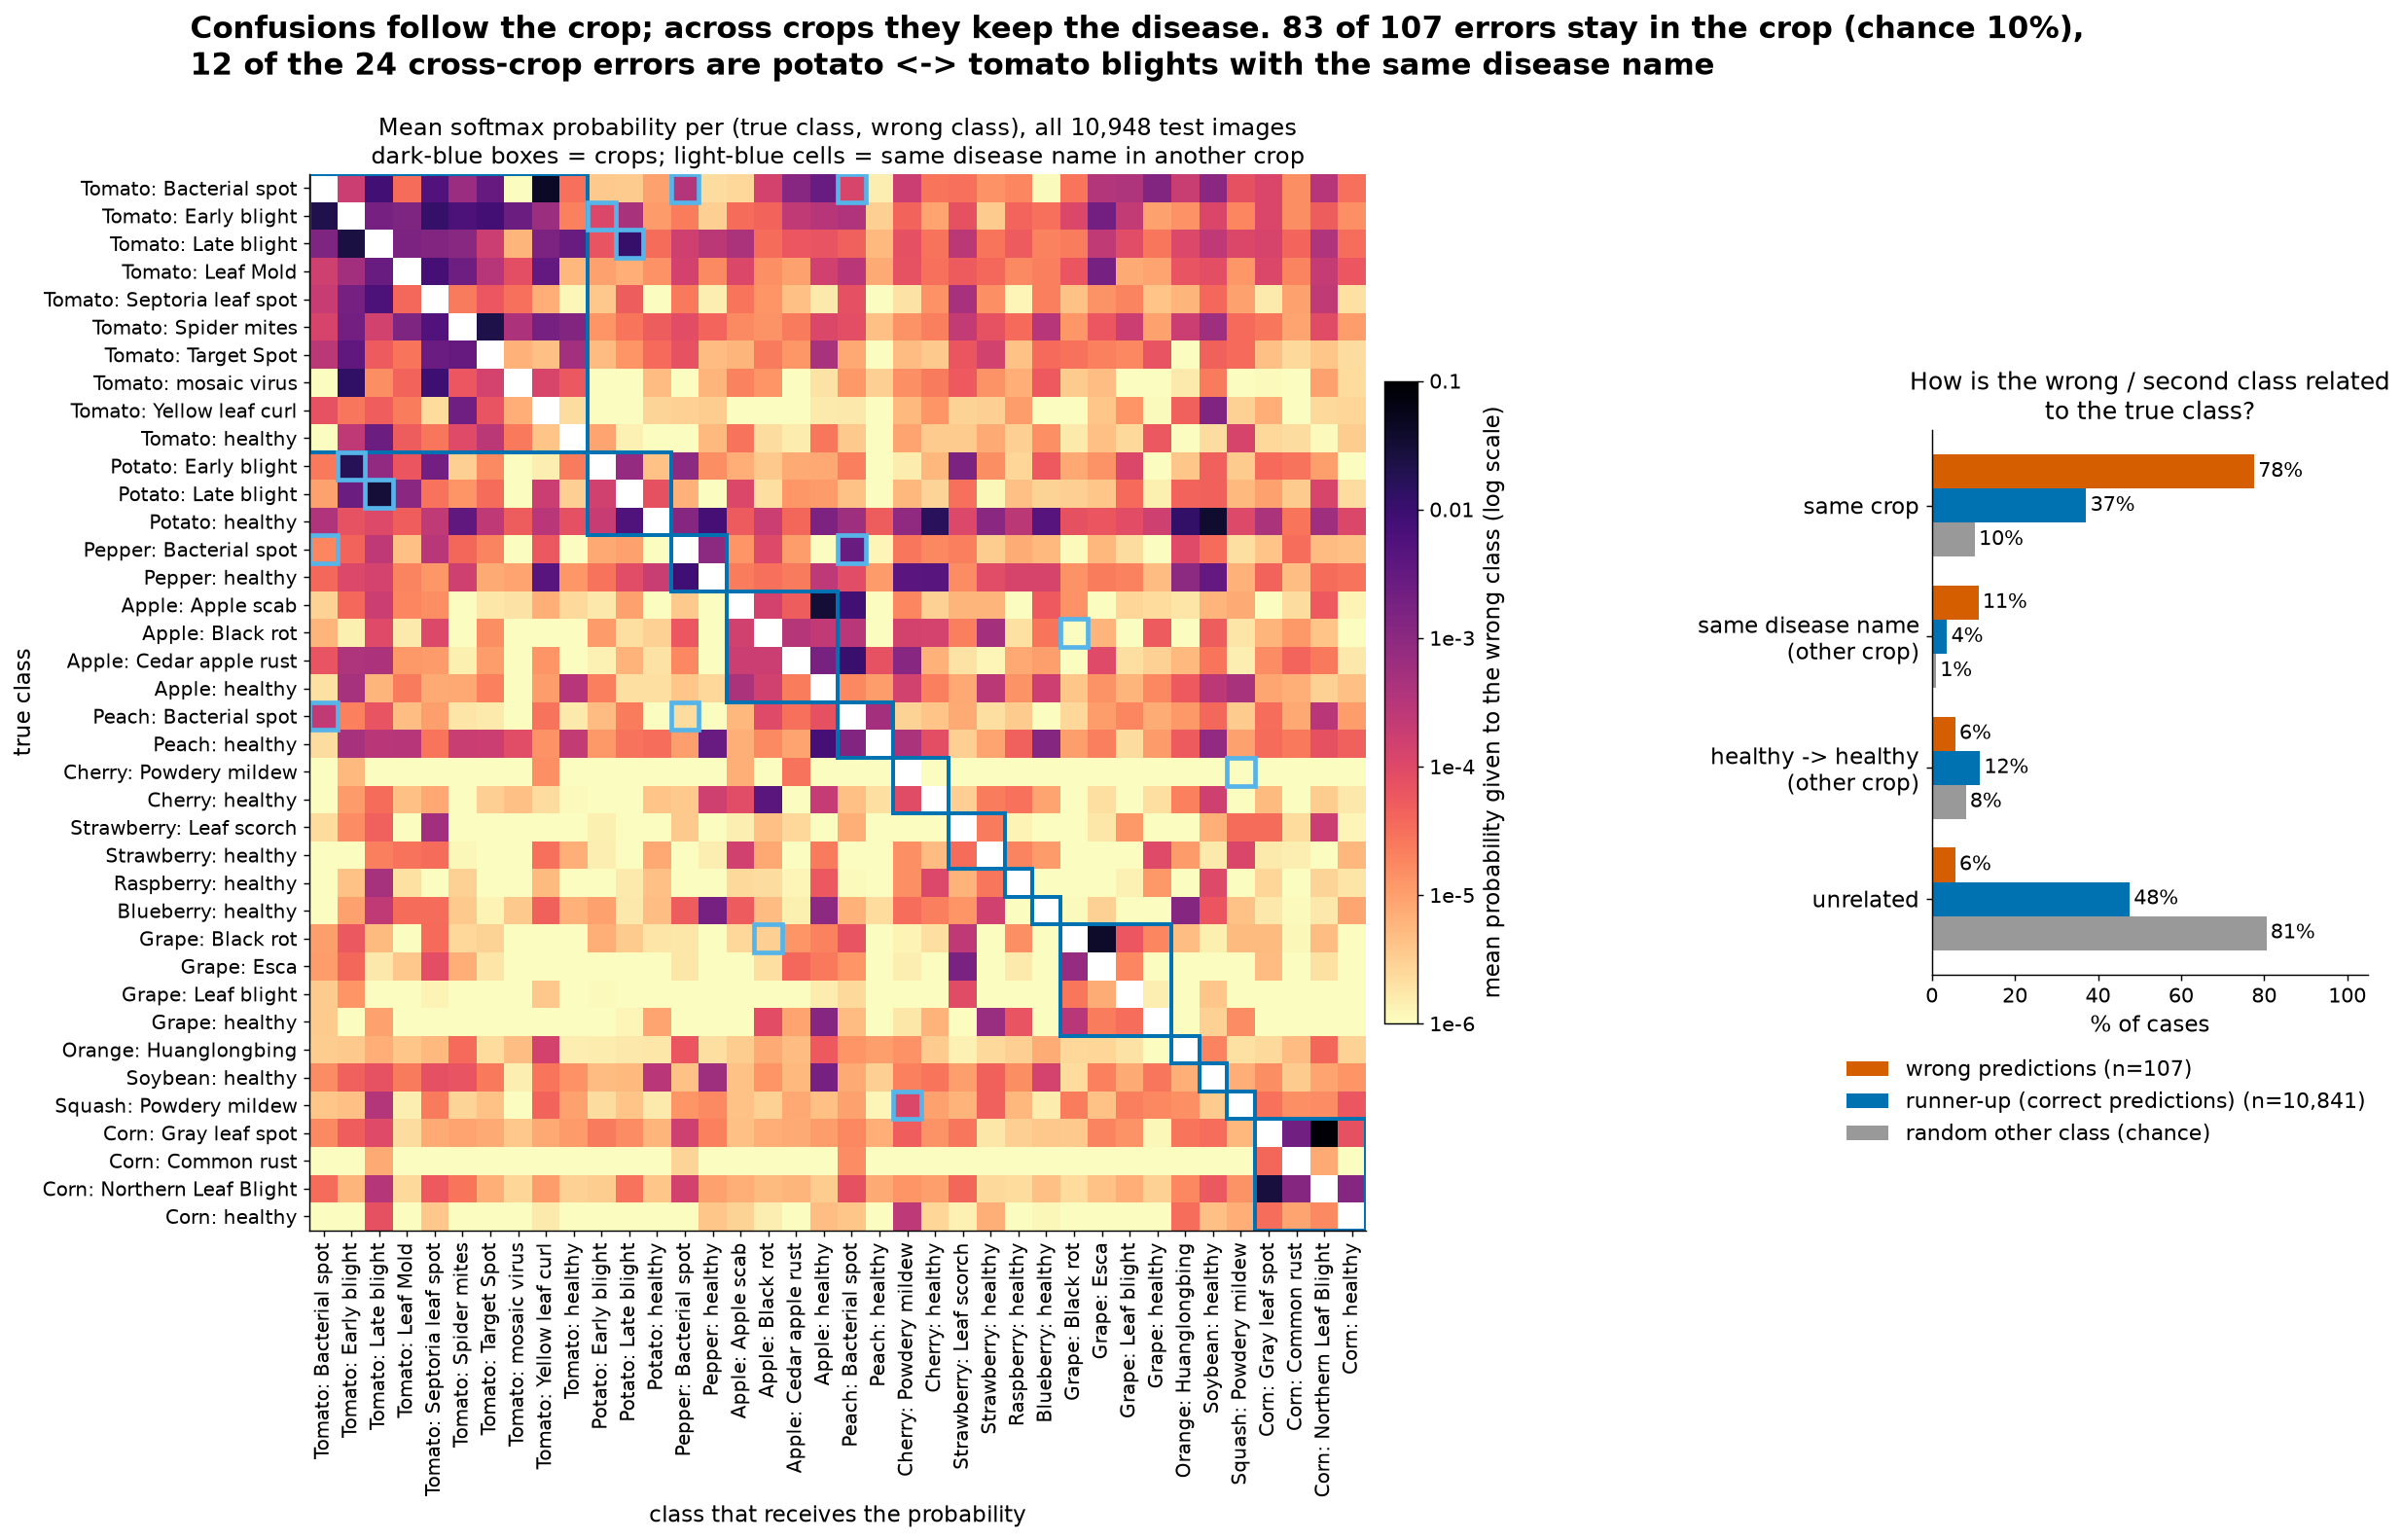

,wrong predictions,runner-up (correct predictions),wrong predictions %,runner-up (correct predictions) %,random other class %
same crop,83,4028,77.6,37.2,10.3
same disease name\n(other crop),12,397,11.2,3.7,1.0
healthy -> healthy\n(other crop),6,1255,5.6,11.6,8.2
unrelated,6,5161,5.6,47.6,80.5


In [3]:
tab, shares = figures.fig_soft_confusion(sh, names, FIG / "fig1_confusion_structure.png")
display(Image(filename=str(FIG / "fig1_confusion_structure.png")))
display(tab.assign(**{c + " %": (100 * shares[c]).round(1) for c in shares.columns}))

**Finding.** Confusions follow the plant first and the disease second.
- 83 of the 107 errors (78%) stay within the crop, although only 10% of the wrong classes a random error could pick are in the same crop.
- Of the 24 cross-crop errors, 12 keep the disease name (potato late blight <-> tomato late blight 5 + 3, potato early blight -> tomato early blight 4),
  6 are "healthy" -> "healthy" of another crop, and only 6 are unrelated.
- The same structure is visible in correct predictions: the runner-up class is in the same crop 37% of the time (chance 10%) and has the same
  disease name in another crop 3.7% of the time (chance 1.0%). So this is how the model organises the classes, not just a property of a few errors.
- The biggest single confusion, Tomato bacterial spot -> Tomato yellow leaf curl (18 errors), is the bright cell in the tomato block.

**Follow-up.** Is the bacterial spot -> yellow leaf curl confusion spread over many photos, or due to a few leaves? (Section 2.)

## 2. Are the errors random photos, or specific leaves?

PlantVillage photographs each physical leaf several times. For 7,399 test images we know the leaf (`leaf_grouped=True`,
1,328 leaves, about 5.6 photos per leaf). If errors were caused by the photo (angle, light), they would spread over many leaves.
If they are caused by the leaf itself, they cluster. We test this against a simulation that keeps the number of errors per
class but places them on random photos of that class. Then we look at the largest confusion (Tomato bacterial spot -> yellow
leaf curl, 18 errors) with a simple colour description of the leaf (mean Lab colour inside a leaf mask, `04_leaf_descriptors.py`).

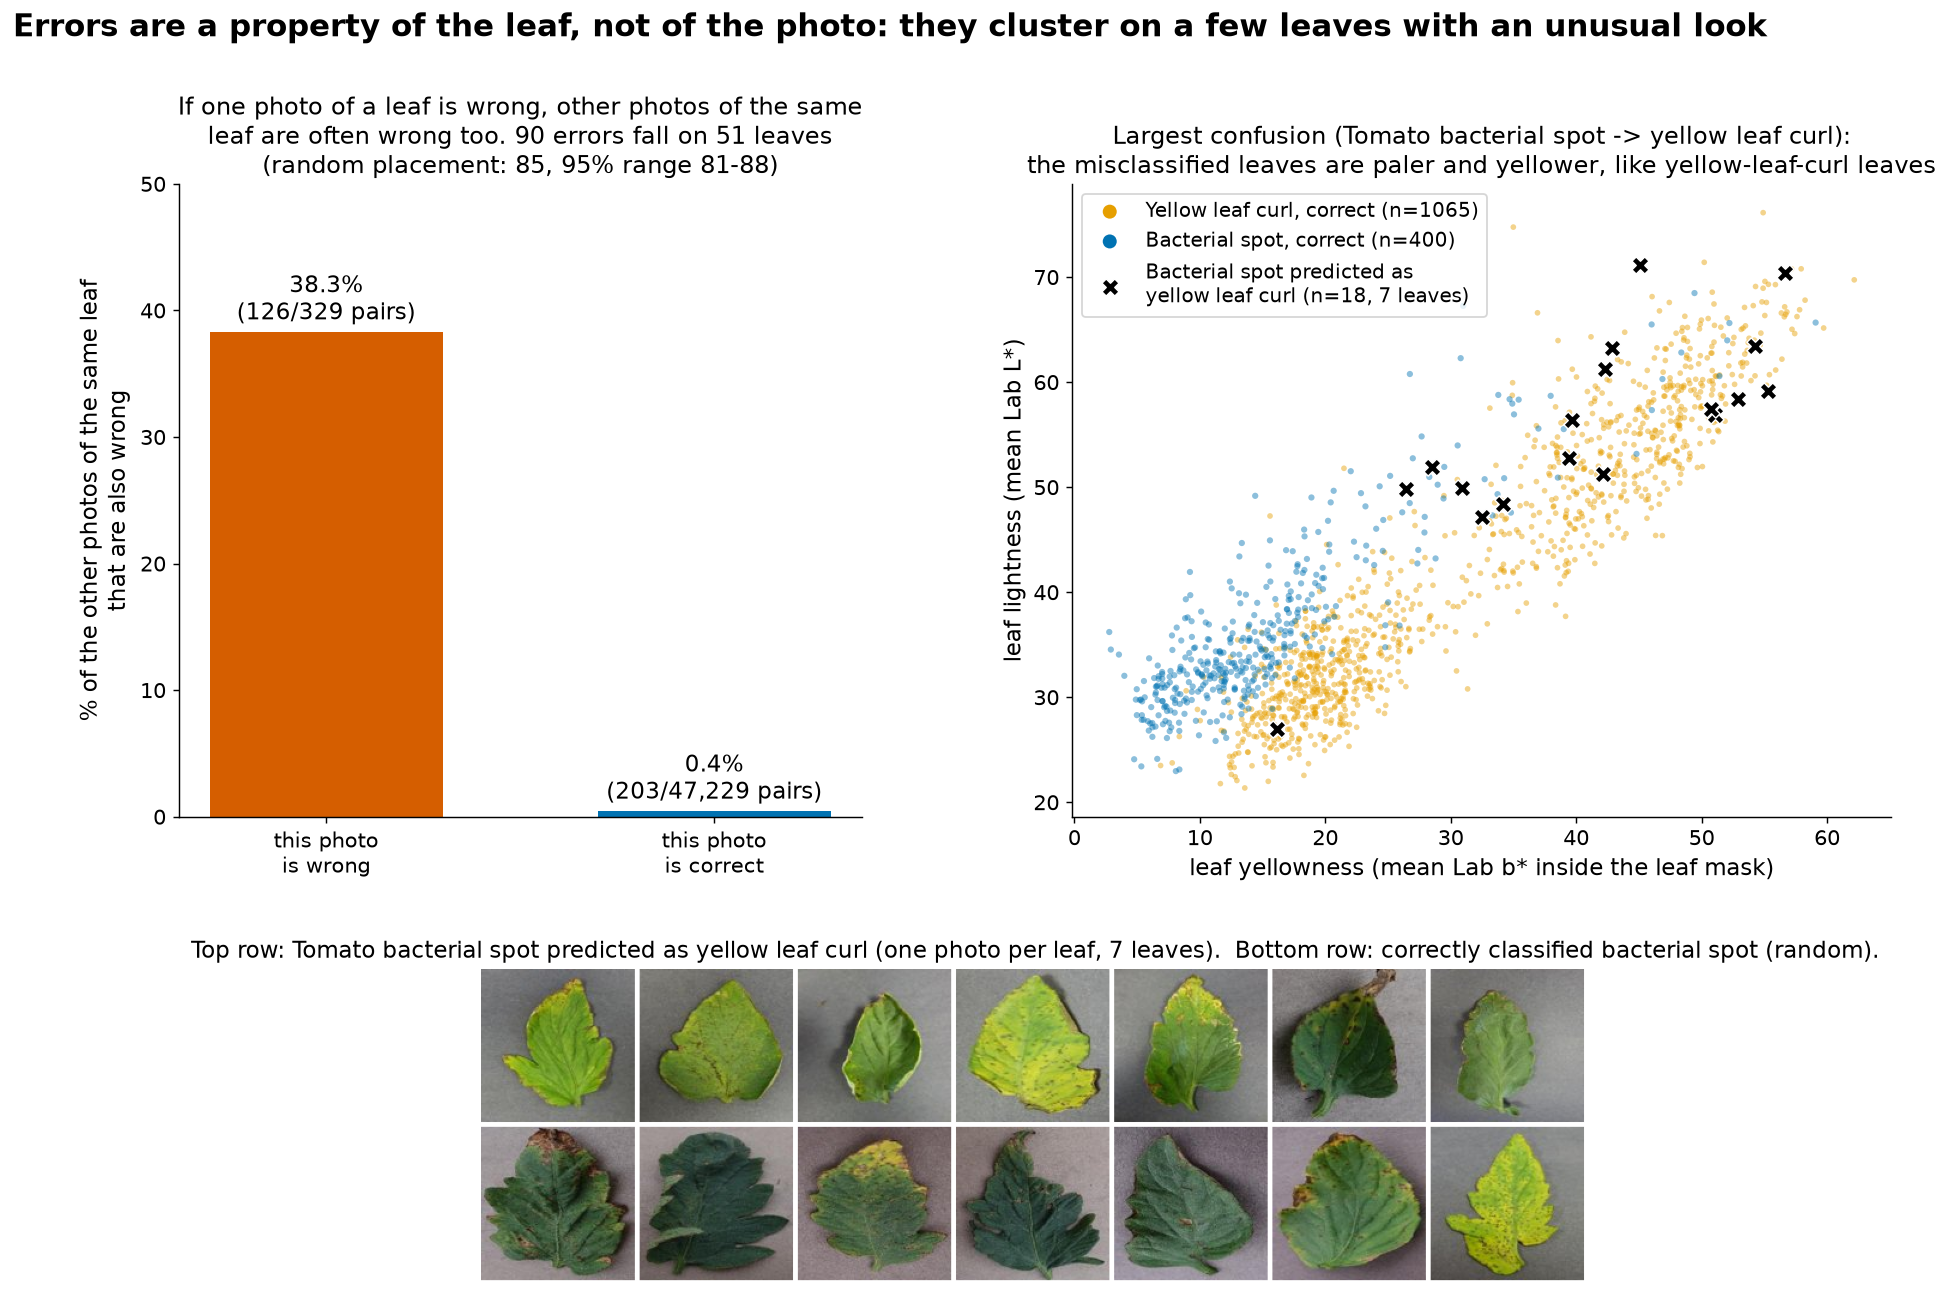

{'n_grouped_images': 7399, 'n_leaves': 1328, 'n_errors': 90, 'observed_leaves': 51, 'null_mean': np.float64(84.7388), 'null_lo': np.float64(81.0), 'null_hi': np.float64(88.02499999999964), 'p_value': np.float64(0.0001999600079984003)}
errors per leaf (leaves with >=1 error): {1: 29, 2: 12, 3: 3, 4: 7}
leaves wrong in every photo: 5 | their photo counts: [4, 4, 4, 4, 4]
{'p_other_wrong_given_wrong': np.float64(0.3829787234042553), 'pairs_wrong': (126, 329), 'p_other_wrong_given_correct': np.float64(0.004298206610345339), 'pairs_correct': (203, 47229), 'error_rate_grouped': 0.01216380591971888}
{'tbs_correct_b': 13.4, 'tbs_err_b': 42.2, 'ylcv_b': 27.6, 'tbs_correct_L': 34.1, 'tbs_err_L': 56.6, 'ylcv_L': 40.0, 'n_tbs_err': 18.0, 'n_tbs_err_leaves': 7.0}


In [4]:
desc = pd.read_parquet(pv.RESULTS / "test_leaf_descriptors.parquet")
th128 = figures.load_thumbs(128)
lc, cond, st = figures.fig_errors_by_leaf(sh, names, desc, figures.tbs_strip(sh, th128), FIG / "fig2_errors_by_leaf.png")
display(Image(filename=str(FIG / "fig2_errors_by_leaf.png")))
print({k: v for k, v in lc.items() if k not in ("sims", "errors_per_leaf")})
print("errors per leaf (leaves with >=1 error):", lc["errors_per_leaf"].value_counts().sort_index().to_dict())
g = sh[sh.leaf_grouped].groupby("leaf_id").correct.agg(["size", "sum"])
print("leaves wrong in every photo:", int(((g["sum"] == 0)).sum()), "| their photo counts:", g[g["sum"] == 0]["size"].tolist())
print(cond)
print({k: round(float(v), 1) for k, v in st.items()})

**Finding.** Errors belong to leaves, not to photos.
- The 90 errors on grouped leaves fall on only 51 distinct leaves; random placement within the class would give 85 leaves (95% range 81-88, p < 0.001).
- If one photo of a leaf is wrong, 38.3% of the other photos of the same leaf are wrong too (126 of 329 pairs). If the photo is correct, only 0.4% are
  (203 of 47,229). Five leaves are wrong in every photo.
- The 18 bacterial spot -> yellow leaf curl errors come from 7 leaves. In a simple colour description of the leaf area (input description, not the model)
  these leaves are much paler and yellower than correctly classified bacterial spot leaves (median b* 42 vs 13; L* 57 vs 34) and lie inside the
  cloud of yellow-leaf-curl leaves (b* 28). Yellowing is a typical yellow-leaf-curl symptom, so the model's choice is understandable from the leaf colour.

**Caveat.** The colour descriptor depends on our leaf mask; we checked the masks visually on 76 random images. Leaf colour is a correlate, not
proof of what the model uses; Section 3 tests colour changes directly.

**Follow-up.** If leaf appearance (colour, brightness) drives errors, then changing colour and brightness on purpose should produce the same kind of
errors. (Section 3.)

## 3. How do lighting, colour, sharpness and geometry change the predictions?

The test images were all taken under similar studio conditions, so natural errors are rare. To see systematic behaviour we change
the inputs in a controlled way (`02_perturbation_sweep.py`): 18 kinds of change, each at 4 strengths, applied to a stratified
subset of 40 test images per class (1,512 images; Potato healthy has only 32). Every modified image is compared with the same
image unmodified, run through the same CPU pipeline. One built-in control: a 180° rotation equals a horizontal plus vertical flip,
which the model saw during training, so it should change almost nothing. The preview strip in the interactive explorer shows each
change on one example leaf.

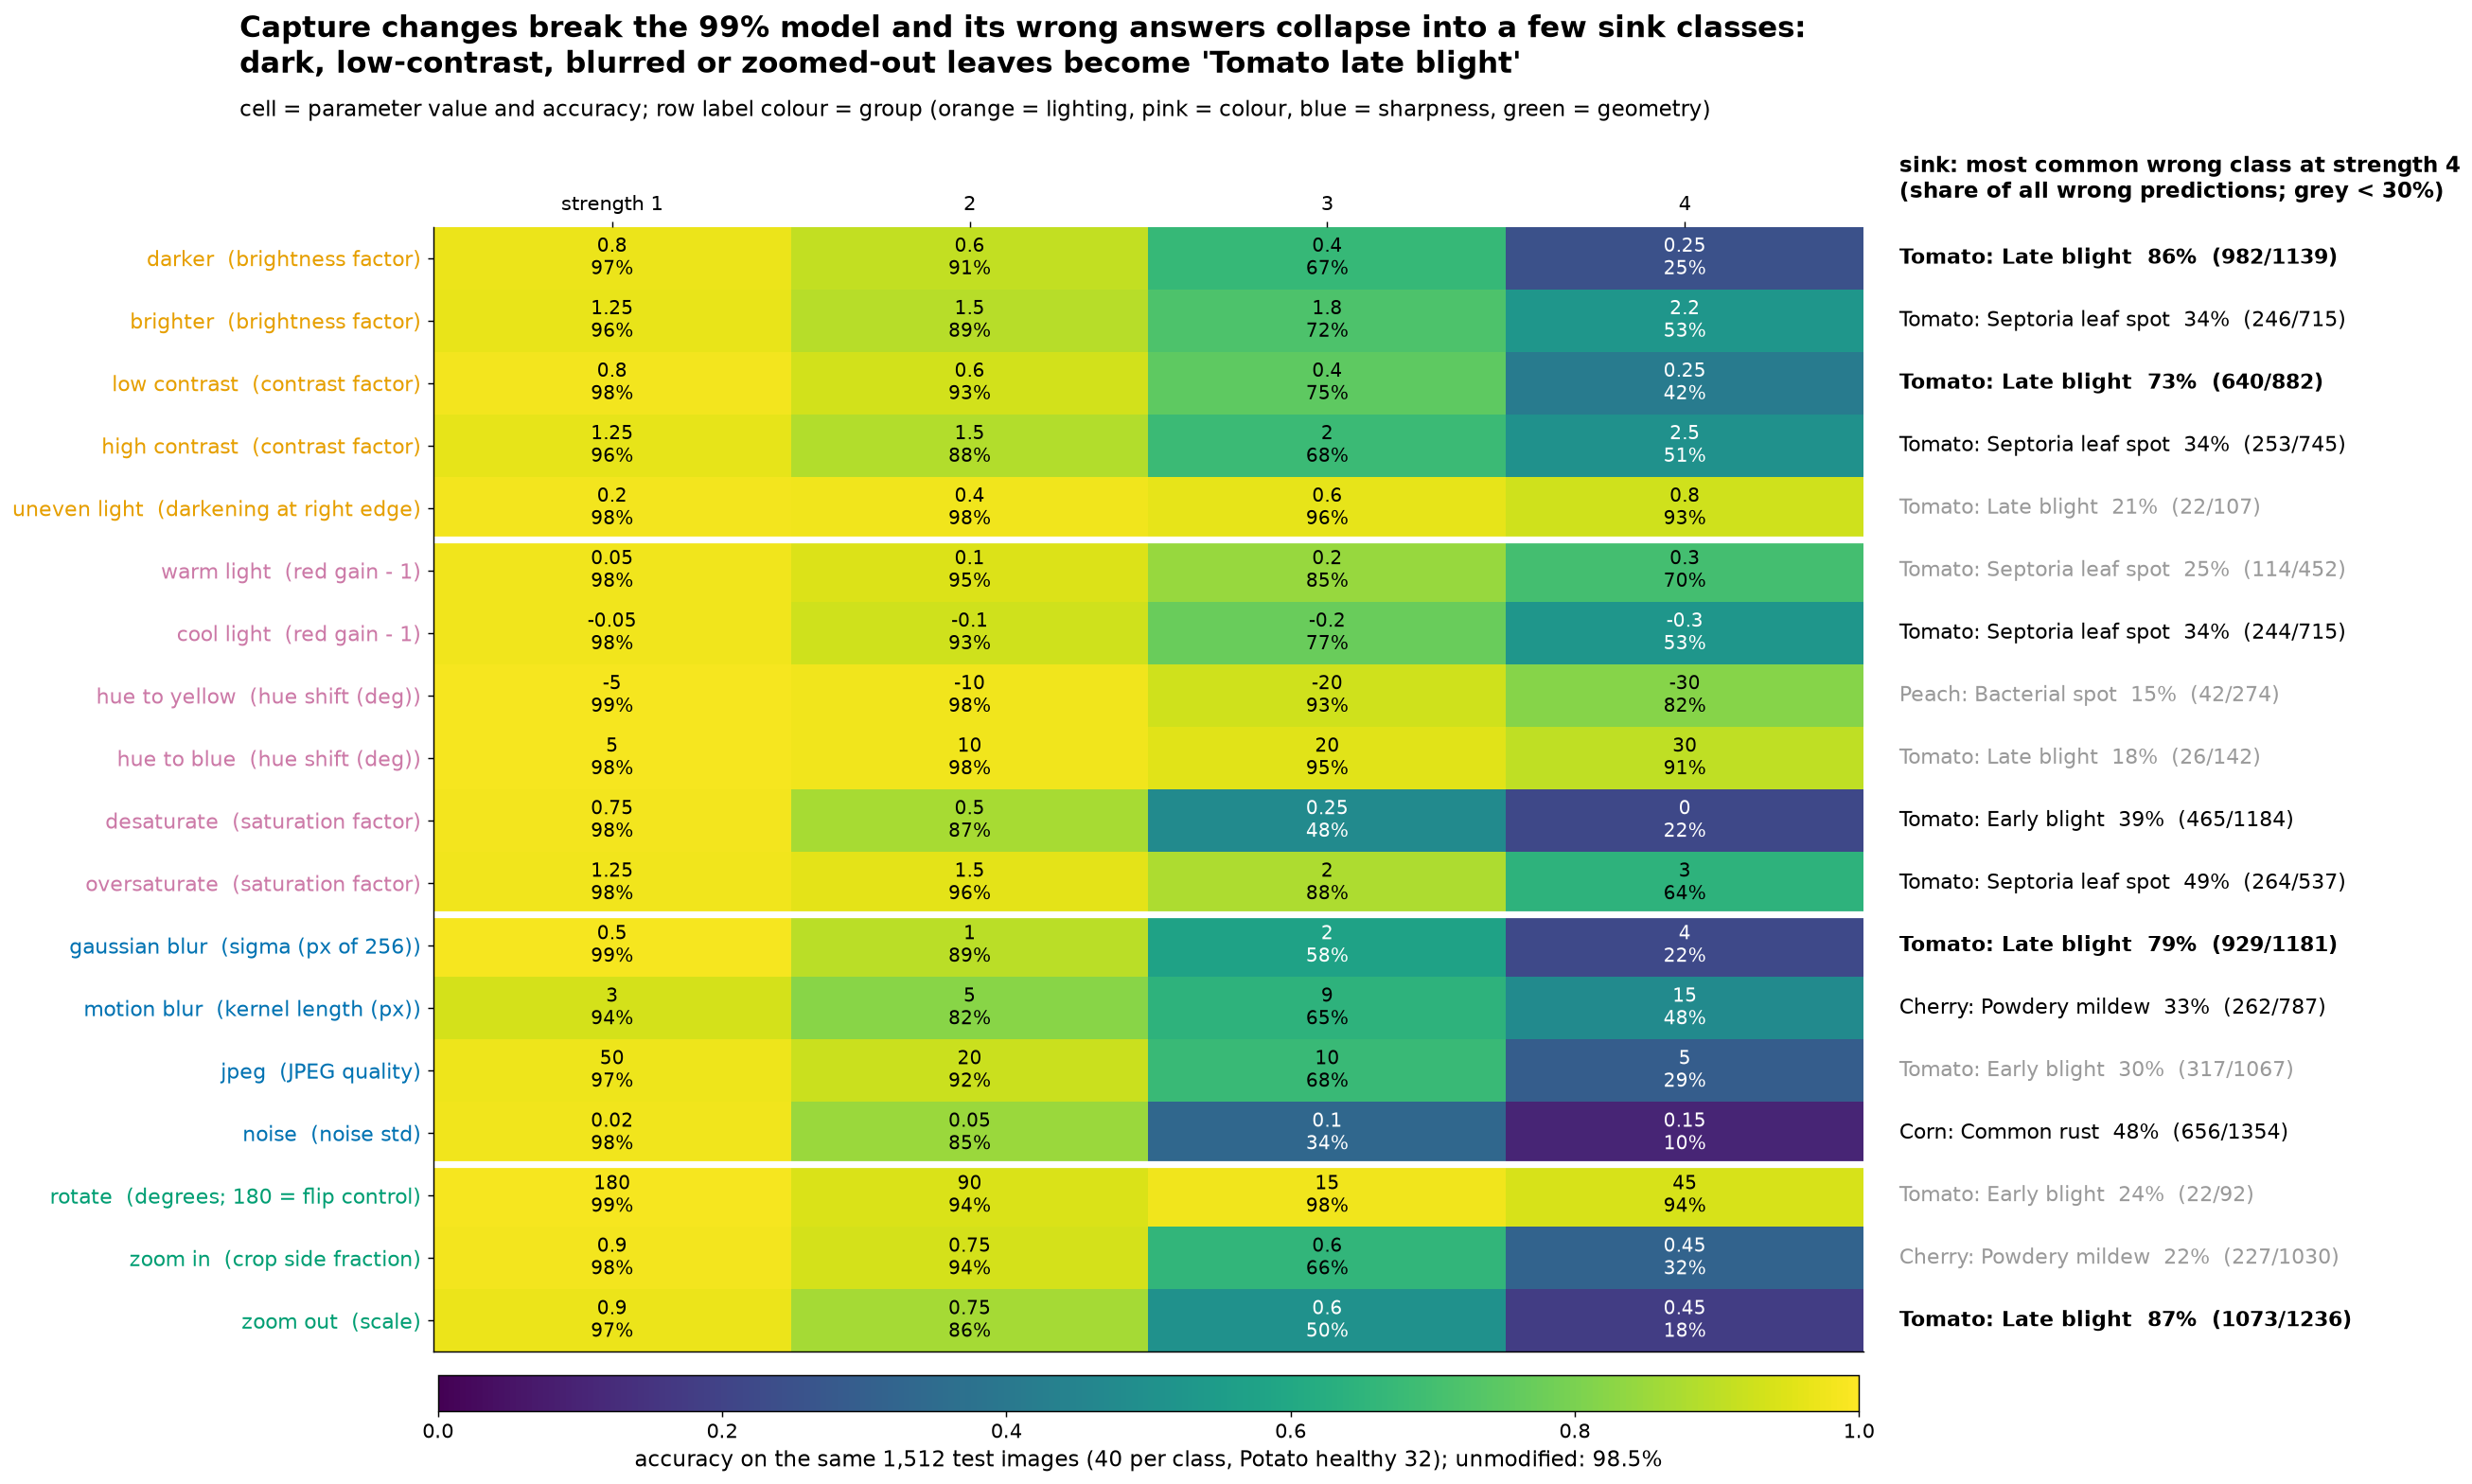

,family,rank,level,acc,acc_lo,acc_hi,flip_rate,sink,sink_share,median_conf_wrong
0,none,0,0.00,0.985,0.978,0.990,0.000,Tomato: Early blight,0.227,0.790
1,darker,1,0.80,0.972,0.963,0.979,0.015,Apple: healthy,0.119,0.785
2,darker,2,0.60,0.909,0.893,0.922,0.081,Apple: healthy,0.188,0.704
3,darker,3,0.40,0.671,0.647,0.695,0.325,Tomato: Late blight,0.439,0.676
4,darker,4,0.25,0.247,0.226,0.269,0.753,Tomato: Late blight,0.862,0.897
...,...,...,...,...,...,...,...,...,...,...
68,zoom in,4,0.45,0.319,0.296,0.343,0.679,Cherry: Powdery mildew,0.220,0.732
69,zoom out,1,0.90,0.970,0.960,0.977,0.024,Tomato: Early blight,0.239,0.736
70,zoom out,2,0.75,0.864,0.846,0.881,0.130,Tomato: Late blight,0.478,0.706
71,zoom out,3,0.60,0.504,0.479,0.529,0.493,Tomato: Late blight,0.804,0.822


In [5]:
sw = figures.load_sweep(sh)
sm = figures.sweep_summary(sw, names)
figures.fig_sweep(sm, FIG / "fig3_capture_changes.png")
display(Image(filename=str(FIG / "fig3_capture_changes.png")))
cols = ["family", "rank", "level", "acc", "acc_lo", "acc_hi", "flip_rate", "sink", "sink_share", "median_conf_wrong"]
sm[cols].round(3)

**Finding.** The 99% holds only for studio-like images, and the failures are systematic.
- The model tolerates mild changes (strength 1: 94-99% everywhere) and the flip control (180° rotation: 11 of 1,512 predictions change).
  It is also robust to uneven light (93% at the strongest level) and hue shifts (82-91%).
- It breaks under strong darkening (25%), desaturation (22%), Gaussian blur (22%), noise (10%), heavy JPEG (29%) and zoom (18-32%).
  A 90° rotation costs about 4 points (94%), so orientation matters a little although flips were trained.
- Wrong predictions do not spread over the 37 other classes. At strengths 3-4 there are 21,164 wrong predictions and three tomato classes take
  51% of them: Tomato late blight 27%, Septoria leaf spot 14%, early blight 10%.
- The sink depends on the kind of change: dark, low-contrast, strongly blurred and zoomed-out images go to **Tomato late blight** (73-87% of the
  wrong predictions at strength 4); bright, high-contrast, oversaturated and noisy images go to **Septoria leaf spot** (34-51%, noise at the
  strongest level to Corn common rust).

**Context.** The baseline was trained with random horizontal and vertical flips only (`shared/baseline.ipynb`), no colour, blur or rotation
augmentation, so these changes are outside what the model has seen.

**Caveat.** Zoom-out pads with the border colour, so part of its effect is the visible frame. Strengths are not comparable across rows; the cell
shows the parameter value for that reason.

**Follow-up.** Why late blight? (Section 4.) Which classes are most fragile, and is the model at least unsure when it is wrong (next cells)?

In [6]:
# supporting table (no figure; the explorer shows the per-class detail): which classes change their prediction most?
import perturb
fams = list(perturb.FAMILIES)
d3 = sw[(sw["rank"] == 3) & sw.family.isin(fams)]
frag = d3.groupby("true_idx").flipped.mean().sort_values(ascending=False)
ft = pd.DataFrame({"class": [short[i] for i in frag.index], "% changed (mean over 18 changes, strength 3)": (100 * frag.values).round(1)})
pd.concat([ft.head(6), ft.tail(4)])

,class,"% changed (mean over 18 changes, strength 3)"
0,Tomato: Target Spot,62.4
1,Potato: healthy,59.2
2,Pepper: healthy,46.9
3,Cherry: healthy,43.9
4,Tomato: Spider mites,41.4
5,Potato: Early blight,40.6
34,Corn: healthy,9.2
35,Corn: Common rust,7.4
36,Orange: Huanglongbing,5.8
37,Cherry: Powdery mildew,5.0


Fragility differs by class: at strength 3, Tomato target spot (62% of predictions change on average over the 18 changes), Potato healthy (59%) and
Pepper healthy (47%) are the most fragile; Corn common rust (7%), Orange huanglongbing (6%) and Cherry powdery mildew (5%) hardly change.
The explorer shows the full class x condition detail.

In [7]:
# follow-up: which controlled changes reproduce the natural Tomato bacterial spot -> yellow leaf curl confusion? (40 bacterial spot images)
tbs = sw[sw.true_idx == 28]
t = tbs.groupby(["family", "rank", "level"]).apply(lambda d: pd.Series({
        "n": len(d), "predicted yellow leaf curl": int((d.pred_idx == 35).sum()), "accuracy": round(d.correct.mean(), 3)}),
        include_groups=False).reset_index()
show = t.sort_values("predicted yellow leaf curl", ascending=False).head(6)
colour = t[t.family.isin(["hue to yellow", "warm light", "brighter", "desaturate"]) & (t["rank"] == 3)]
pd.concat([show, colour])

,family,rank,level,n,predicted yellow leaf curl,accuracy
18,gaussian blur,3,2.00,40.0,25.0,0.275
43,motion blur,4,15.00,40.0,17.0,0.425
19,gaussian blur,4,4.00,40.0,12.0,0.000
42,motion blur,3,9.00,40.0,11.0,0.650
17,gaussian blur,2,1.00,40.0,8.0,0.800
41,motion blur,2,5.00,40.0,6.0,0.850
2,brighter,3,1.80,40.0,0.0,0.200
14,desaturate,3,0.25,40.0,0.0,0.575
30,hue to yellow,3,-20.00,40.0,3.0,0.900
63,warm light,3,0.20,40.0,2.0,0.900


In [8]:
# does the confidence warn us when a modified image is misclassified?
from sklearn.metrics import roc_auc_score
pm = sw[sw.family != "none"]
wm = pm[~pm.correct]
conf_tab = pd.DataFrame({
    "natural test set (10,948)": [f"{(~sh.correct).sum():,}", f"{100 * (sh.confidence[~sh.correct] > 0.9).mean():.0f}%",
                                  f"{roc_auc_score(sh.correct, sh.confidence):.3f}"],
    "all 72 modified conditions": [f"{len(wm):,}", f"{100 * (wm.confidence > 0.9).mean():.0f}%",
                                   f"{roc_auc_score(pm.correct, pm.confidence):.3f}"]},
    index=["wrong predictions", "wrong predictions with confidence > 0.9", "AUROC of confidence (correct vs wrong)"])
display(conf_tab)
sink_conf = {f: f"{100 * (pm[(pm.family == f) & (pm['rank'] == 4) & ~pm.correct].confidence > 0.9).mean():.0f}%"
             for f in ["darker", "zoom out", "gaussian blur", "noise"]}
print("strength 4, share of wrong predictions with confidence > 0.9:", sink_conf)
p34 = pm[(pm["rank"] >= 3) & ~pm.correct]
vc = p34.pred_idx.value_counts()
print(f"strength 3-4: {len(p34):,} wrong predictions; top sinks:",
      [(short[i], int(n), f"{100 * n / len(p34):.1f}%") for i, n in vc.head(5).items()])

,"natural test set (10,948)",all 72 modified conditions
wrong predictions,107,"24,111"
wrong predictions with confidence > 0.9,40%,31%
AUROC of confidence (correct vs wrong),0.971,0.877


strength 4, share of wrong predictions with confidence > 0.9: {'darker': '49%', 'zoom out': '58%', 'gaussian blur': '41%', 'noise': '10%'}
strength 3-4: 21,164 wrong predictions; top sinks: [('Tomato: Late blight', 5694, '26.9%'), ('Tomato: Septoria leaf spot', 2941, '13.9%'), ('Tomato: Early blight', 2108, '10.0%'), ('Cherry: Powdery mildew', 1289, '6.1%'), ('Apple: healthy', 978, '4.6%')]


**Finding.**
- The natural bacterial spot -> yellow leaf curl confusion is reproduced by **blur**, not by colour: Gaussian blur with sigma 2 sends 25 of 40 bacterial
  spot images to yellow leaf curl, while yellowing hue shifts, warm light or brightening at strength 3 send almost none. A plausible reading: blur removes
  the small dark spots, and a spot-free pale tomato leaf looks like yellow leaf curl to the model. The natural errors (paler leaves, Section 2) fit this:
  spots are less visible on a pale leaf.
- Confidence does not flag the shifted inputs. On modified images, 31% of wrong predictions still have confidence > 0.9 (natural errors: 40%), and
  the ranking quality of confidence drops from AUROC 0.971 to 0.877. Wrong predictions into the late-blight sink are especially confident
  (darker: 49%, zoom out: 58% above 0.9).

## 4. Why do darkened images become "Tomato late blight"?

Tomato late blight is the strongest sink in the sweep (dark, low-contrast, blurred and zoomed-out images); we follow up on darkening,
the clearest case. Two questions: (a) where could this come from in the training data
(the training data is allowed as a source of hypotheses), and (b) which part of the image triggers it? For (b) we use leaf masks
(`segment.py`, colour distance to the border plus GrabCut, checked visually on 76 random images) and darken only the leaf, only
the background, or the whole image, and we put the unmodified leaf on flat grey or black (`05_background_tests.py`). 1,427 of the
1,512 subset images have a usable mask; we also drop Corn healthy, whose close-up photos have no visible background (found in the visual
mask check), which leaves 1,400 images.

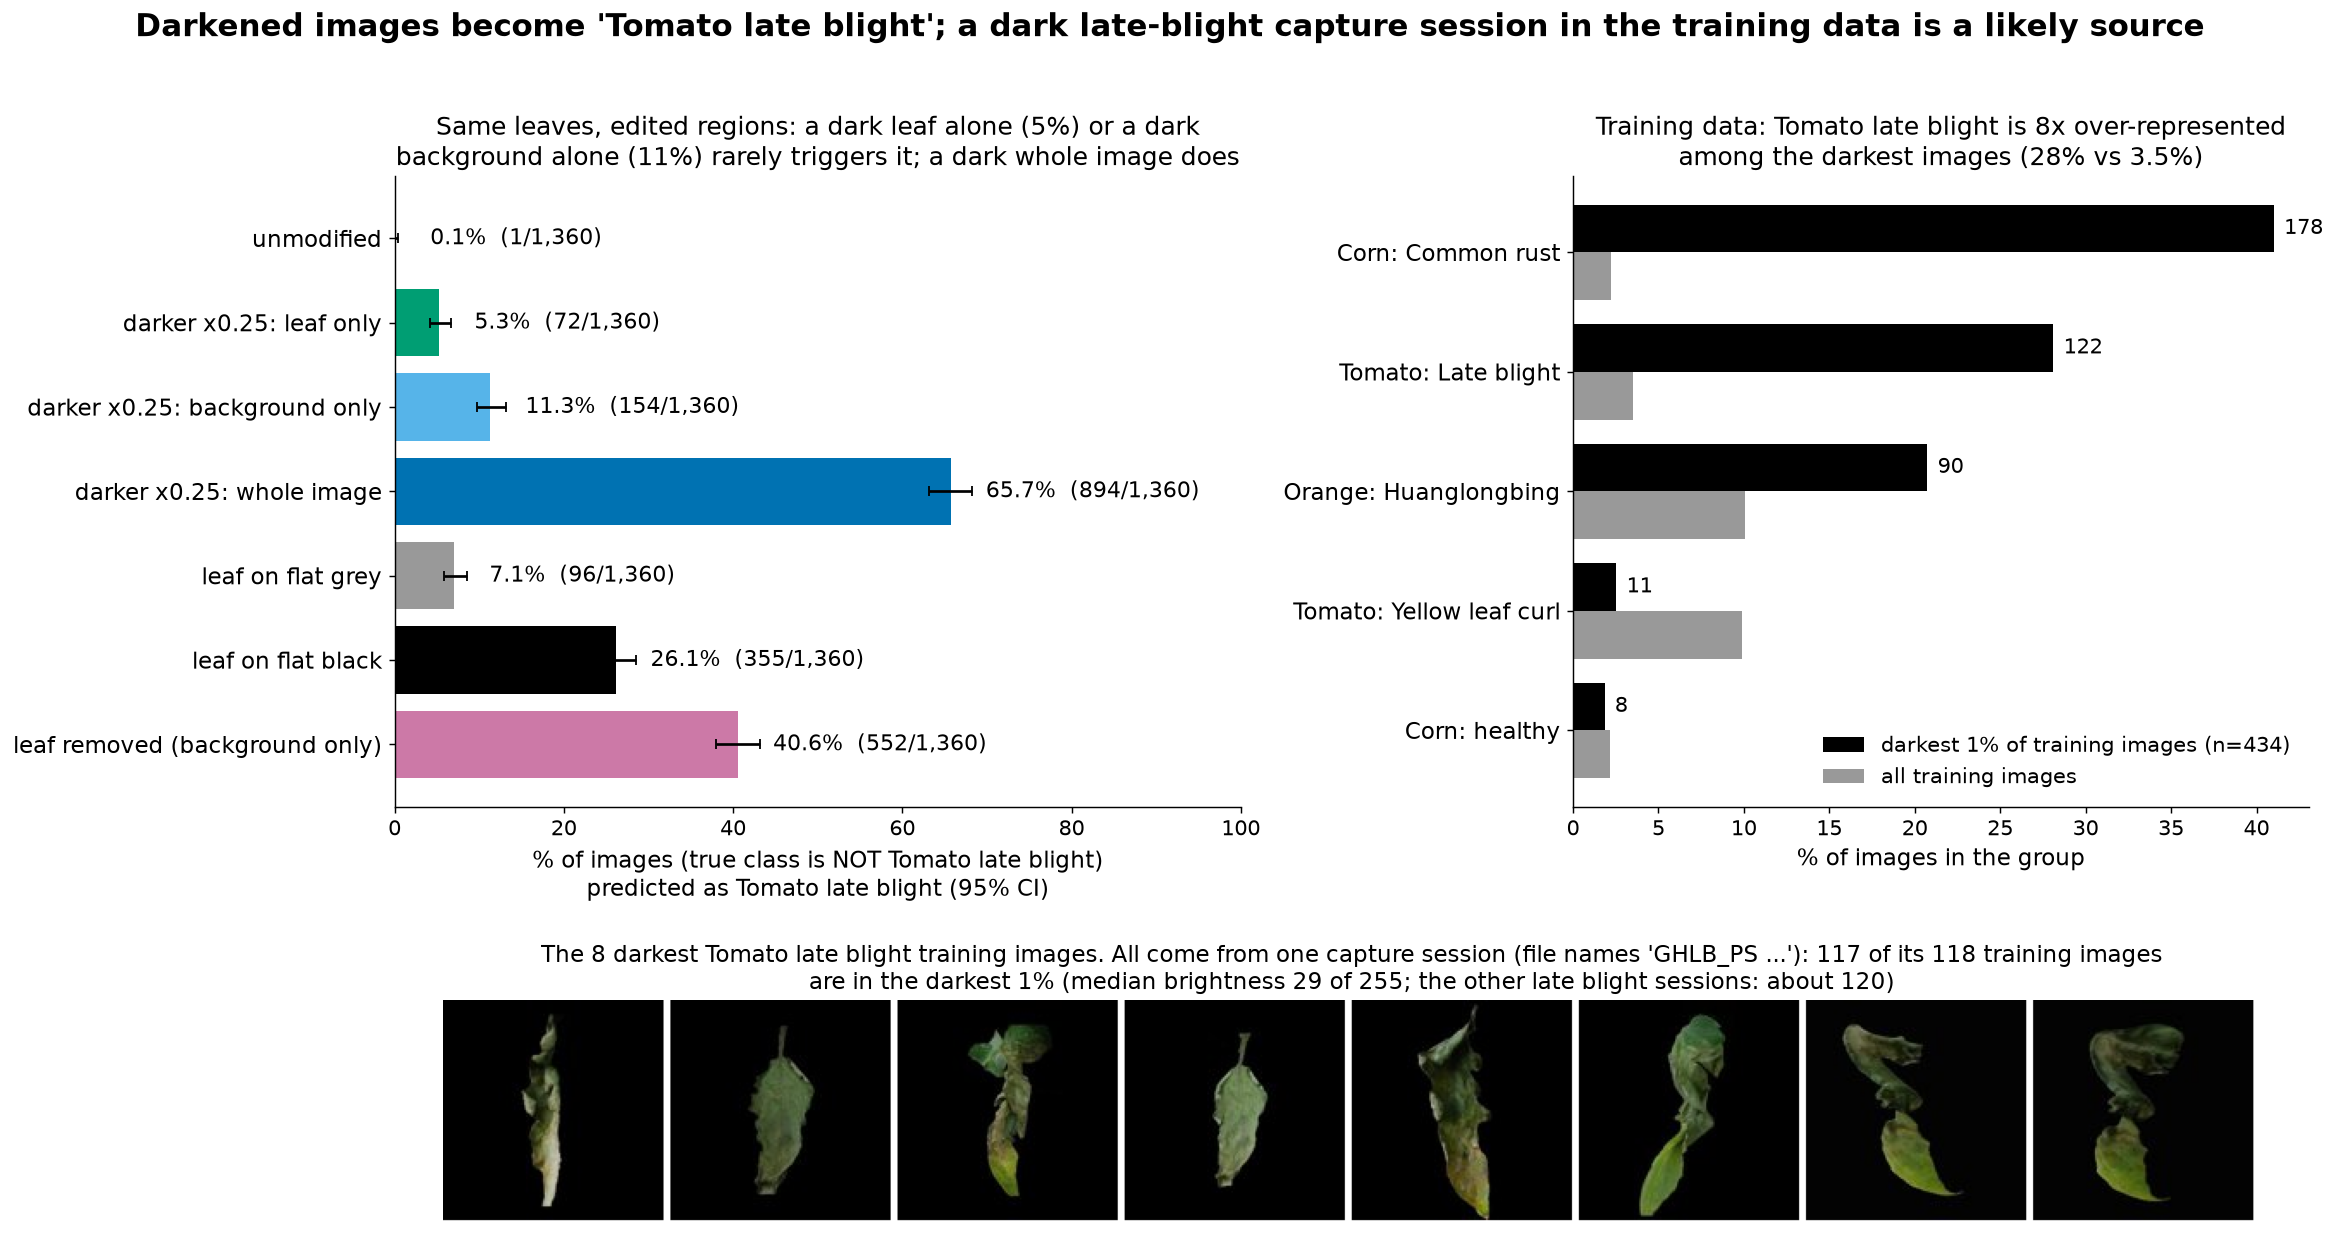

sweep, non-late-blight images predicted as Tomato late blight:
family  rank  level    n   k
darker     1   0.80 1472   2
darker     2   0.60 1472  23
darker     3   0.40 1472 218
darker     4   0.25 1472 982
  none     0   0.00 1472   1
                                   n    k   pct
condition                                      
background corners only         1240   33   2.7
background only                 1360  552  40.6
brighter x2.2: background only  1360   33   2.4
brighter x2.2: leaf only        1360   22   1.6
brighter x2.2: whole image      1360   52   3.8
darker x0.25: background only   1360  154  11.3
darker x0.25: leaf only         1360   72   5.3
darker x0.25: whole image       1360  894  65.7
leaf on black                   1360  355  26.1
leaf on grey                    1360   96   7.1
leaf on white                   1360   64   4.7
original                        1360    1   0.1
swap: other class               2679   45   1.7
swap: same class                1360    5  

In [9]:
bg = figures.load_background()   # Corn healthy excluded: close-ups without visible background
br = pd.read_parquet(pv.RESULTS / "image_brightness.parquet")
nums = figures.dark_sink_numbers(sw, bg, br, names)
te = pd.read_parquet(pv.RESULTS / "train_examples.parquet")
from PIL import Image as PILImage
tt = {k: np.asarray(PILImage.open(io.BytesIO(b)).convert("RGB")) for k, b in enumerate(te.jpeg)}
ses = json.loads((pv.RESULTS / "late_blight_sessions.json").read_text())
figures.fig_dark_sink(nums, names, figures.thumb_strip([list(range(len(tt)))], tt), ses, FIG / "fig4_dark_late_blight.png")
display(Image(filename=str(FIG / "fig4_dark_late_blight.png")))
print("sweep, non-late-blight images predicted as Tomato late blight:")
print(nums["darker"].to_string(index=False))
print(nums["background"].assign(pct=lambda d: (100 * d.k / d.n).round(1)).to_string())
print("darkest 1% of training images: luminance <=", round(nums["train_dark_q"], 1), "n =", nums["train_dark_n"])
print(json.dumps(ses, indent=1))

**Finding.**
- Darkening the whole image to 25% sends 66% of the images of *other* classes to Tomato late blight (894 of 1,360). Darkening only the leaf (5%)
  or only the background (11%) rarely does. So the trigger is the overall dark image, not one region alone.
- A flat black background around an unmodified leaf already sends 26% there, flat grey 7%. With the leaf removed (only the inpainted background),
  41% of the images go to Tomato late blight, so late blight is the model's default answer for "no recognisable leaf" as well.
- Training data: Tomato late blight makes up 28% of the darkest 1% of training images but 3.5% of all training images. 117 of these 122 images come from
  one capture session (file names "GHLB_PS ..."), photographed on black: 117 of its 118 images are in the darkest 1% (median brightness 29 of 255, other
  late blight sessions about 120). The test set has 32 images from the same session.

**Interpretation (hypothesis).** The model has learned "very dark image -> late blight" from this session. Corn common rust is even more over-represented
among dark training images (178), but darkened leaves rarely go there, probably because the leaf shape (long, narrow) does not match; a leaf of another class on flat black
does go to corn common rust in 201 of 1,400 cases (14%). We cannot prove the causal link in Phase I without retraining; it is a lead for Phase II
(where does the model look on dark images?).

## 5. Does the model use the background?

PlantVillage was photographed in sessions, and the background colour differs between sessions. Noyan (2022, arXiv:2206.04374)
reached 49% test accuracy on PlantVillage with a model that only saw 8 background pixels. We first check that this bias exists in
our split with a simple input statistic (median colour of a 6 px border frame, 15-nearest-neighbour on the training images; this
is *not* our model). Then we ask our model, using outputs only: (a) what does it predict when the leaf is removed, and (b) does
the prediction for the same leaf change when we paste it onto the background of another image? The same-class background swap
is the control for pasting artefacts.

border colour only, all 10,948 test images: accuracy 0.513, crop accuracy 0.612, chance 0.026, majority class 0.106


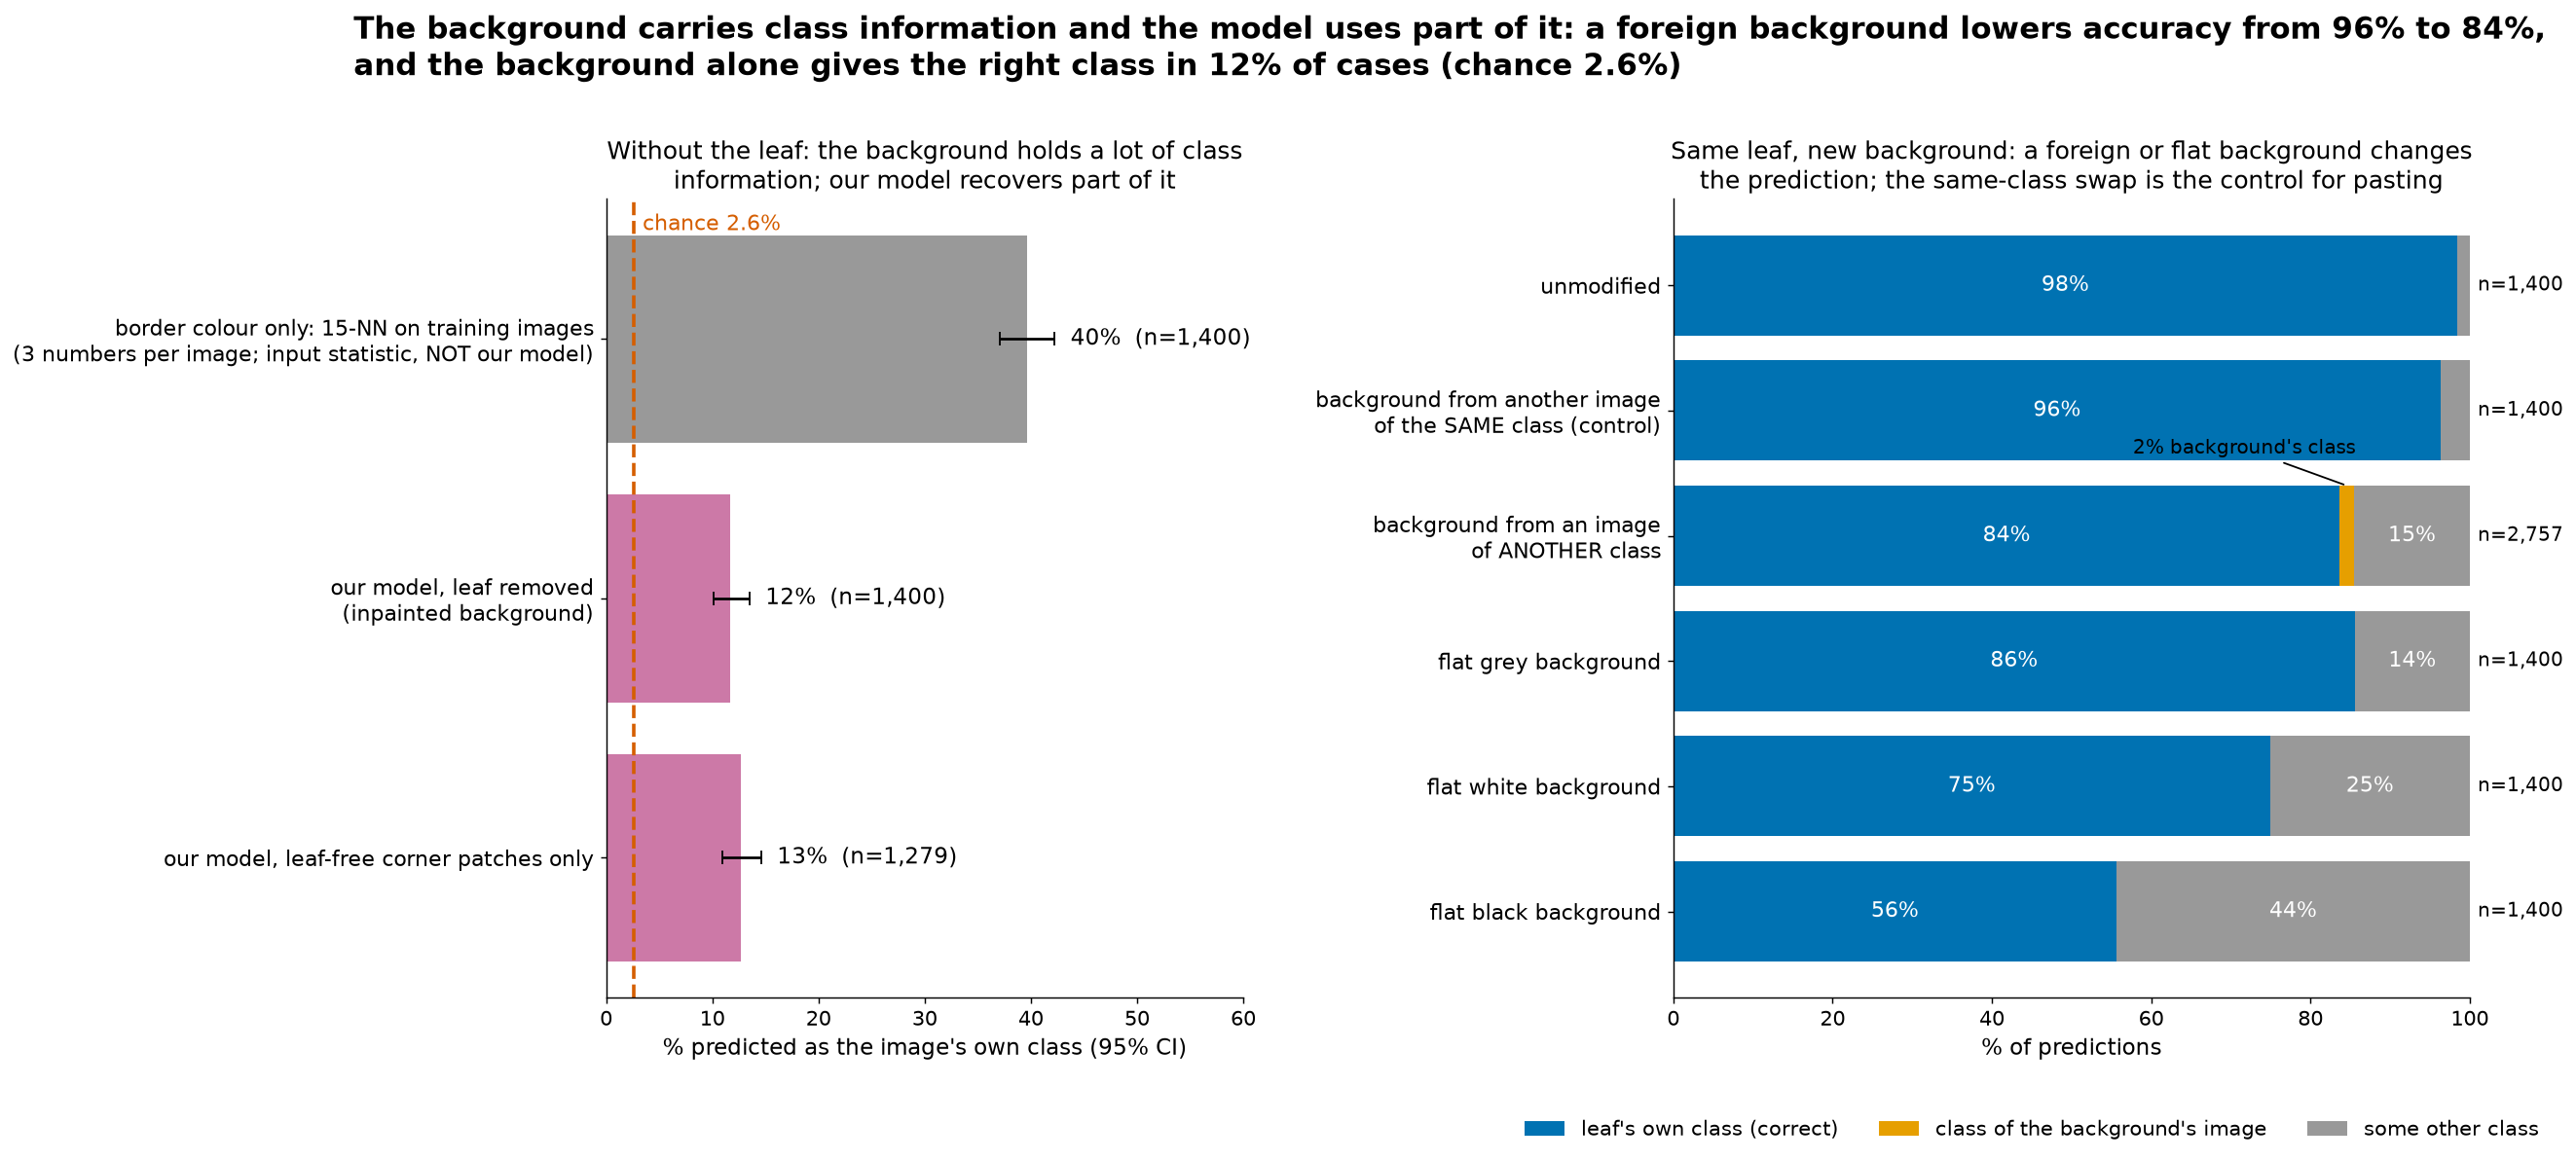

,n,leaf_class,donor_class,other,acc
condition,,,,,
background corners only,1279,162,0,1117,0.126661
background only,1400,164,0,1236,0.117143
brighter x2.2: background only,1400,1107,0,293,0.790714
brighter x2.2: leaf only,1400,1060,0,340,0.757143
brighter x2.2: whole image,1400,721,0,679,0.515000
darker x0.25: background only,1400,1155,0,245,0.825000
darker x0.25: leaf only,1400,810,0,590,0.578571
darker x0.25: whole image,1400,350,0,1050,0.250000
leaf on black,1400,779,0,621,0.556429


In [10]:
knn = json.loads((pv.RESULTS / "border_knn.json").read_text())
print(f"border colour only, all 10,948 test images: accuracy {knn['test_accuracy']:.3f}, crop accuracy {knn['test_crop_accuracy']:.3f}, "
      f"chance {knn['chance_uniform']:.3f}, majority class {knn['chance_majority_class']:.3f}")
S, knn_acc = figures.fig_background(bg, names, FIG / "fig5_background.png")
display(Image(filename=str(FIG / "fig5_background.png")))
S

In [11]:
# which backgrounds hurt most? (swap: other class, grouped by the class of the image the background came from)
sw_o = bg[bg.condition == "swap: other class"]
pull = (sw_o.assign(to_bg=sw_o.pred_idx == sw_o.donor_class, ok=sw_o.pred_idx == sw_o.true_idx)
        .groupby("donor_class").agg(n=("ok", "size"), **{"pred = background's class": ("to_bg", "sum")},
                                    **{"leaf still correct %": ("ok", "mean")}))
pull["leaf still correct %"] = (100 * pull["leaf still correct %"]).round(1)
pull["%"] = (100 * pull["pred = background's class"] / pull.n).round(1)
pull.index = [short[i] for i in pull.index]
pull.sort_values("leaf still correct %").head(8)

,n,pred = background's class,leaf still correct %,%
Corn: Common rust,58,8,58.6,13.8
Corn: Gray leaf spot,74,11,70.3,14.9
Soybean: healthy,74,2,75.7,2.7
Grape: Leaf blight,74,1,77.0,1.4
Tomato: Septoria leaf spot,83,6,77.1,7.2
Apple: Cedar apple rust,71,0,77.5,0.0
Tomato: mosaic virus,74,0,78.4,0.0
Apple: Apple scab,65,1,78.5,1.5


In [12]:
# what does the model predict when it sees only background? (leaf removed)
bo = bg[bg.condition == "background only"]
vc = bo.pred_idx.value_counts().head(6)
display(pd.DataFrame({"predicted class": [short[i] for i in vc.index], "n": vc.values,
                      "% of background-only images": (100 * vc.values / len(bo)).round(1)}))
# for which classes does the background alone give the right answer?
hit = bo.assign(ok=bo.pred_idx == bo.true_idx).groupby("true_idx").ok.agg(["size", "mean"]).sort_values("mean", ascending=False)
pd.DataFrame({"class": [short[i] for i in hit.index], "n": hit["size"].values,
              "% correct from background alone": (100 * hit["mean"].values).round(1)}).head(6)

,predicted class,n,% of background-only images
0,Tomato: Late blight,580,41.4
1,Corn: Northern Leaf Blight,286,20.4
2,Tomato: healthy,115,8.2
3,Corn: Gray leaf spot,108,7.7
4,Apple: healthy,89,6.4
5,Tomato: Septoria leaf spot,75,5.4


,class,n,% correct from background alone
0,Tomato: healthy,40,87.5
1,Tomato: Late blight,40,70.0
2,Corn: Gray leaf spot,35,51.4
3,Corn: Northern Leaf Blight,25,40.0
4,Apple: healthy,40,37.5
5,Squash: Powdery mildew,15,33.3


**Finding.**
- The background alone contains a lot of class information: three numbers (the median border colour) give 51% accuracy on the full test set
  with a 15-NN (40% on this subset), against 2.6% chance. This replicates Noyan (2022) on our split.
- Our model uses part of it. With the leaf removed it still names the right class in 12% of cases (corner patches only: 13%), 4-5x chance; most hits
  are in classes with a distinctive background (Tomato healthy 88%, Corn gray leaf spot 51%). Tomato late blight (70%) is a special case:
  late blight is the default answer for leaf-free images (41% of all of them), so its hits say little.
- Same leaf, new background: with a background from another image of the same class, accuracy stays at 96%; with a background from another class it drops
  to 84% (n = 2,757). Only 2% of the predictions move to the background's own class. Of the 450 wrong predictions, 42% go to the three tomato sink classes from
  Section 3 (early blight 95, Septoria 48, late blight 45).
- Flat backgrounds also hurt: grey 86%, white 75%, black 56%.

**Caveats.** Masks are not perfect. Where they miss part of the background, the "leaf only" edits keep some original background, so these numbers
underestimate the background effect. Corn healthy is excluded (close-ups without background), leaving 1,400 images.

**Follow-up.** Phase II: is the model's attention on the leaf or on the border in background-sensitive classes (Tomato healthy, Corn)?

## 6. Does similarity to the training set (near-duplicates, leakage) explain the accuracy?

This check uses tables only (the result is mostly flat, so a figure adds little).
For 16 classes (3,549 test images) the dataset has no or only partial leaf grouping, so photos of the same leaf can sit in train and test.
We describe each image by a 32x32 colour thumbnail and use the pixel correlation to the most similar training image
(`03_input_space.py`; an input-space measure, not the model's representation). In a visual check of pairs, r > 0.93 looked
like the same or a nearly identical leaf in the same pose, and r below about 0.9 looked like different leaves.

In [13]:
nn = pd.read_parquet(pv.RESULTS / "test_nearest_train.parquet")
d = sh.merge(nn, on="sample_idx")
d["pct"] = d.groupby("true_idx").best_sim_same_class.rank(pct=True)
d["similarity quintile (within class)"] = pd.cut(d.pct, [0, .2, .4, .6, .8, 1.0], labels=["1 least similar", "2", "3", "4", "5 most similar"])
d["closest training image is"] = np.where(d.best_sim_other_class > d.best_sim_same_class, "another class", "own class")
dup = d[d.nn_sim > 0.93]
def rate(g):
    lo, hi = viz.wilson((~g.correct).sum(), len(g))
    return pd.Series({"n": len(g), "errors": int((~g.correct).sum()), "error %": round(100 * (~g.correct).mean(), 2),
                      "95% CI": f"{100 * lo:.2f}-{100 * hi:.2f}"})
display(d.groupby("similarity quintile (within class)", observed=True).apply(rate, include_groups=False))
display(d.groupby("closest training image is").apply(rate, include_groups=False))
print("pixel 1-NN accuracy (input statistic):", round(float((d.nn_class == d.true_idx).mean()), 3))
print("near-copies (r > 0.93):", len(dup), "| without leaf grouping:", int((~dup.leaf_grouped).sum()),
      "| errors:", int((~dup.correct).sum()))
d[(d.nn_sim > 0.93) & (d.nn_class != d.true_idx)][["sample_idx", "true_label", "nn_class", "nn_sim", "pred_label", "leaf_id"]]

,n,errors,error %,95% CI
similarity quintile (within class),,,,
1 least similar,2175,22,1.01,0.67-1.53
2,2189,25,1.14,0.77-1.68
3,2191,25,1.14,0.77-1.68
4,2189,21,0.96,0.63-1.46
5 most similar,2204,14,0.64,0.38-1.06


,n,errors,error %,95% CI
closest training image is,,,,
another class,4263,77,1.81,1.45-2.25
own class,6685,30,0.45,0.31-0.64


pixel 1-NN accuracy (input statistic): 0.611
near-copies (r > 0.93): 135 | without leaf grouping: 80 | errors: 1


,sample_idx,true_label,nn_class,nn_sim,pred_label,leaf_id
8252,8252,Tomato___Late_blight,37,0.974033,Tomato___healthy,Tomato___Late_blight::d674cbf6-0cdc-407a-97ea-...


**Finding.** Leakage through near-copies is real but small, and it does not explain the accuracy.
- 135 test images have a near-copy in training (r > 0.93). 80 of them are in classes without leaf grouping, where the same leaf can be in both splits.
  Only 1 of the 135 is misclassified.
- Errors hardly depend on how close the nearest same-class training image is (error rate 1.0%, 1.1%, 1.1%, 1.0%, 0.6% from least to most similar quintile).
- Errors are 4x more common when the most similar training image (in pixels) belongs to another class: 1.8% (77 of 4,263) vs 0.45% (30 of 6,685).
- The one cross-class near-copy is sample 8252: a "Tomato late blight" test photo (file GH_HL Leaf 170) almost identical to a "Tomato healthy" training
  photo (GH_HL Leaf 170.1). The model says healthy. This looks like a labelling problem in the dataset, not a model error.

**Caveat.** Pixel similarity misses re-photographed leaves that are rotated or shifted, so 135 is a lower bound on near-copies.

## 7. Interactive view: behaviour explorer

[`behaviour_explorer.html`](behaviour_explorer.html) is a self-contained offline page (open it in a browser after cloning; GitHub
does not render it). Linked views: (1) a grid of all conditions (original test set, 72 capture changes, 14 background tests),
coloured by accuracy; (2) the true x predicted matrix for the selected condition with the diagonal hidden, so every coloured cell
is a confusion; (3) bars of wrong predictions per predicted class, which make sink classes visible; (4) thumbnails of the images
behind any clicked cell or bar, with confidence, plus a preview of the selected change. The screenshot shows darkening x0.25 with
the Tomato late blight column selected.

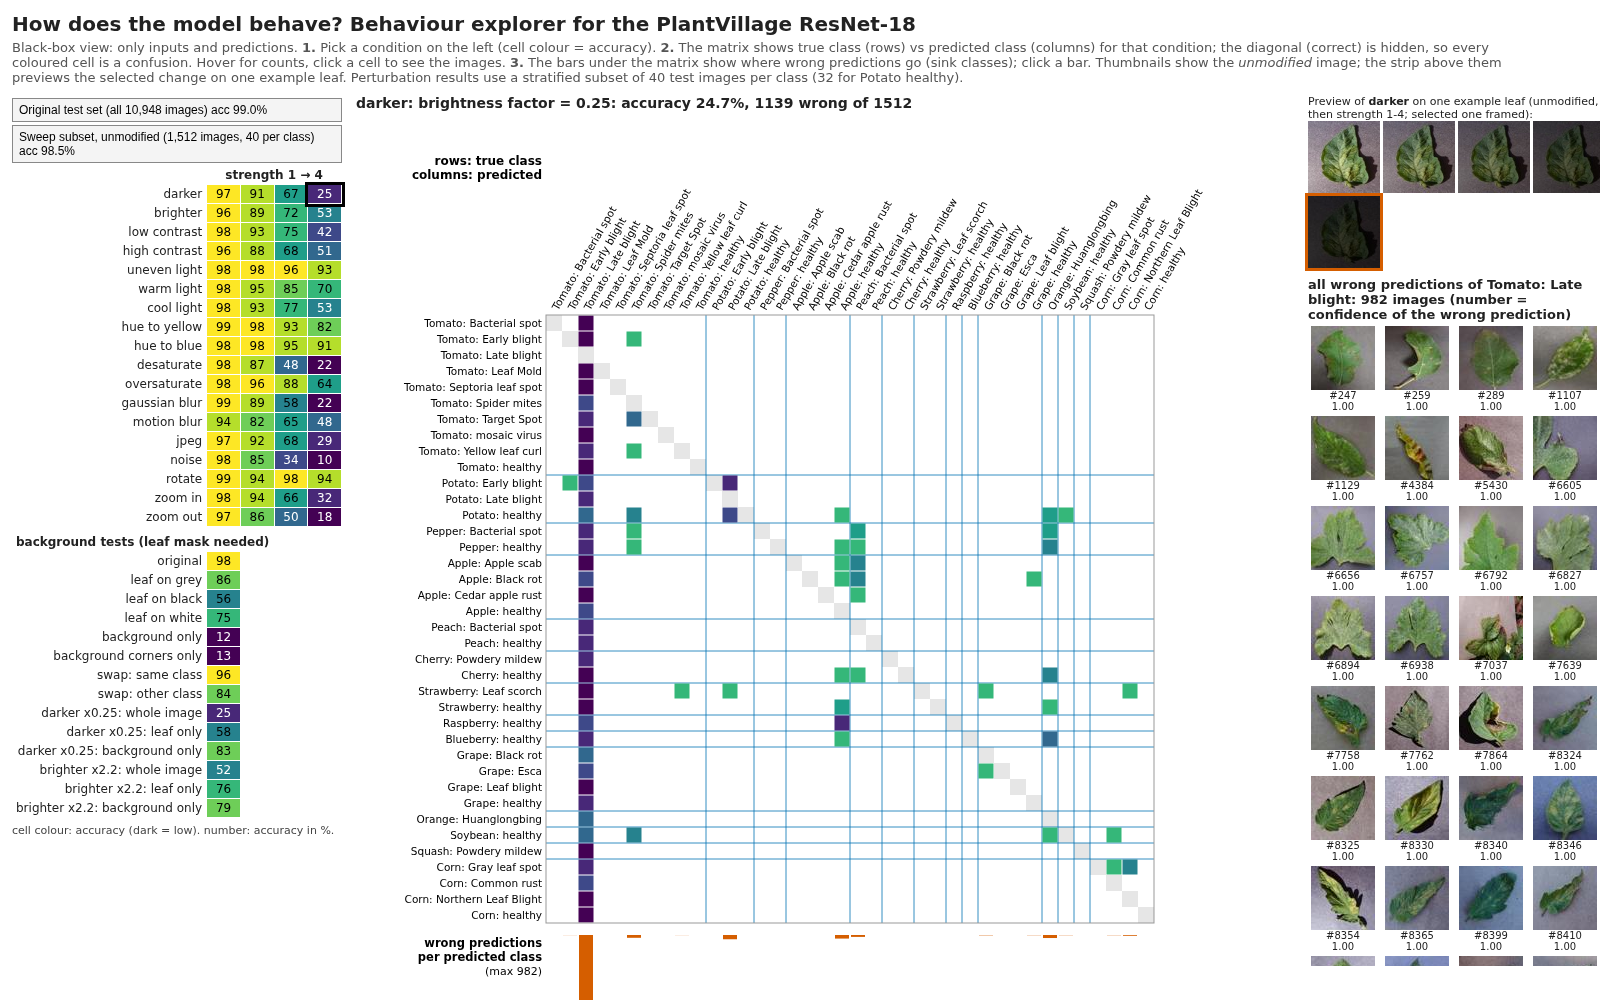

In [14]:
display(Image(filename=str(FIG / "explorer_screenshot.png")))

## 8. What we take from Phase I

- The model's 99% is real on PlantVillage-style images, and its few errors are meaningful: they follow plant and disease similarity and sit on a few unusual leaves.
- Outside the studio conditions the model fails in a structured way: it falls back to a few "sink" classes, mostly Tomato late blight, Septoria leaf spot
  and early blight, and it stays confident while doing so. This matters more than the accuracy number for any use on field photos.
- At least one sink has a traceable cause in the training data (a dark late-blight capture session), and the background carries class information
  that the model partly uses. Both are dataset shortcuts that a test accuracy cannot reveal.

**Open questions for Phase II (model internals):**
1. On darkened and blurred images, does the model look at the leaf or at the image as a whole? (saliency on sink predictions)
2. In the embedding space, are the sink classes "central" (close to everything degraded)? Is Tomato late blight close to the dark training session?
3. For background-sensitive classes (Tomato healthy, Corn), where is the attention on the original image?
4. Are the 51 error leaves outliers in the embedding space, or near the class they are confused with?

**Limitations.** Perturbations use a stratified subset (40 per class), not the whole test set. Leaf masks are a classical segmentation, checked visually
but imperfect; Corn healthy is excluded from background tests. Input descriptions (thumbnails, border colour, leaf colour) describe the images, not the model.
We used the training data only to form hypotheses; nothing was trained or tuned.

In [15]:
# key numbers used in README.md and ai_reflection_midpoint.md (written here so all three agree)
key = {
    "errors": int(len(err)), "errors_within_crop": int(len(err) - len(cross)),
    "cross_crop_same_disease": int(tab.loc["same disease name\n(other crop)", "wrong predictions"]),
    "cross_crop_healthy_to_healthy": int(tab.loc["healthy -> healthy\n(other crop)", "wrong predictions"]),
    "runner_up_same_crop_pct": round(100 * float(shares.loc["same crop", "runner-up (correct predictions)"]), 1),
    "chance_same_crop_pct": round(100 * float(shares.loc["same crop", "random other class"]), 1),
    "grouped_errors": int(lc["n_errors"]), "grouped_error_leaves": int(lc["observed_leaves"]),
    "null_leaves_mean": round(float(lc["null_mean"]), 1), "null_leaves_95": [round(float(lc["null_lo"])), round(float(lc["null_hi"]))],
    "p_other_wrong_given_wrong_pct": round(100 * cond["p_other_wrong_given_wrong"], 1),
    "p_other_wrong_given_correct_pct": round(100 * cond["p_other_wrong_given_correct"], 1),
    "tbs_ylcv_errors": int(st["n_tbs_err"]), "tbs_ylcv_leaves": int(st["n_tbs_err_leaves"]),
    "tbs_b_median": {"correct": round(st["tbs_correct_b"], 1), "error": round(st["tbs_err_b"], 1), "ylcv": round(st["ylcv_b"], 1)},
    "sweep_n": int(sm.loc[sm.family == "none", "n"].iloc[0]),
    "sweep_ref_acc": round(float(sm.loc[sm.family == "none", "acc"].iloc[0]), 4),
    "sweep": {f"{r.family}|{r.rank}": {"level": float(r.level), "acc": round(float(r.acc), 3),
              "flip": round(float(r.flip_rate), 3), "sink": r.sink, "sink_share": round(float(r.sink_share), 3)}
              for r in sm.itertuples() if r.family != "none"},
    "background": {k: {"n": int(v.n), "acc": round(float(v.acc), 3),
                       "donor": round(float(v.donor_class / v.n), 3)} for k, v in S.iterrows()},
    "border_knn_test_acc": round(knn["test_accuracy"], 3), "border_knn_subset_acc": round(knn_acc, 3),
    "dark_sink": {k: {"k": int(v.k), "n": int(v.n)} for k, v in nums["background"].iterrows()},
    "train_dark_n": int(nums["train_dark_n"]), "train_dark_tlb": int(nums["train_dark_counts"].get(30, 0)),
    "train_tlb_share_pct": round(100 * float(nums["train_share"].get(30, 0)), 1),
    "near_copies": int(len(dup)), "near_copy_errors": int((~dup.correct).sum()),
    "err_rate_other_closer_pct": round(100 * float((~d[d["closest training image is"] == "another class"].correct).mean()), 2),
    "err_rate_own_closer_pct": round(100 * float((~d[d["closest training image is"] == "own class"].correct).mean()), 2),
}
(pv.RESULTS / "key_numbers.json").write_text(json.dumps(key, indent=1))
print(json.dumps({k: v for k, v in key.items() if k not in ("sweep", "background", "dark_sink")}, indent=1))

{
 "errors": 107,
 "errors_within_crop": 83,
 "cross_crop_same_disease": 12,
 "cross_crop_healthy_to_healthy": 6,
 "runner_up_same_crop_pct": 37.2,
 "chance_same_crop_pct": 10.3,
 "grouped_errors": 90,
 "grouped_error_leaves": 51,
 "null_leaves_mean": 84.7,
 "null_leaves_95": [
  81,
  88
 ],
 "p_other_wrong_given_wrong_pct": 38.3,
 "p_other_wrong_given_correct_pct": 0.4,
 "tbs_ylcv_errors": 18,
 "tbs_ylcv_leaves": 7,
 "tbs_b_median": {
  "correct": 13.4,
  "error": 42.2,
  "ylcv": 27.6
 },
 "sweep_n": 1512,
 "sweep_ref_acc": 0.9854,
 "border_knn_test_acc": 0.513,
 "border_knn_subset_acc": 0.396,
 "train_dark_n": 434,
 "train_dark_tlb": 122,
 "train_tlb_share_pct": 3.5,
 "near_copies": 135,
 "near_copy_errors": 1,
 "err_rate_other_closer_pct": 1.81,
 "err_rate_own_closer_pct": 0.45
}
